# Homework 4

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, roc_auc_score

In [8]:
#data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
#!wget $data

# Data Preparation

In [9]:
df = pd.read_csv('course_lead_scoring_2026.csv')

categorical = list(df.dtypes[df.dtypes == 'object'].index)
numerical = list(df.dtypes[df.dtypes != 'object'].index)

# remove target feature
numerical.remove('converted')

missing_val_counts = df.isna().sum()
missing_val_cols = list(missing_val_counts[missing_val_counts > 0].index)

for c in missing_val_cols:
    if c in categorical:
        df[c] = df[c].fillna('NA')
    else:
        df[c] = df[c].fillna(0.0)

# check missing values
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [10]:
# split data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# Q1: ROC AUC feature importance

In [11]:
y_train = df_train['converted'].values

auc_max = -1
col_max = ""
for col in numerical:
    scores = df_train[col].values
    auc = roc_auc_score(y_train, scores)

    # check if auc is negative 
    if auc < 0.5:
        scores = -scores
        auc = roc_auc_score(y_train, scores)

    # update auc_max if necessary
    if auc > auc_max:
        auc_max = auc
        col_max = col

    # print loop results
    print(f'{col}: AUC = {auc:.3f}')

print(f'Max AUC {auc_max:.3f} with column {col_max}')
    


annual_income: AUC = 0.608
number_of_courses_viewed: AUC = 0.723
interaction_count: AUC = 0.765
lead_score: AUC = 0.788
Max AUC 0.788 with column lead_score


# Q2: Training the model

In [12]:
# get y values for each dataset
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

# delete target from data
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [13]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [14]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
converted_decision = (y_pred >= 0.5)

# calculate AUC
round(roc_auc_score(y_val, y_pred), 3)

0.732

# Q3: Precision and Recall

In [15]:
# calculate tp, tn, fp, tp with threshold t and append results to scores
scores = []

threshold = np.linspace(0, 1, 101)

for t in threshold:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_negative).sum()

    scores.append((t, tp, tn, fp, fn))

In [16]:
# convert scores into a dataframe
columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
df_scores = pd.DataFrame(scores, columns=columns)

In [17]:
# calculate precision and recall for every threshold
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

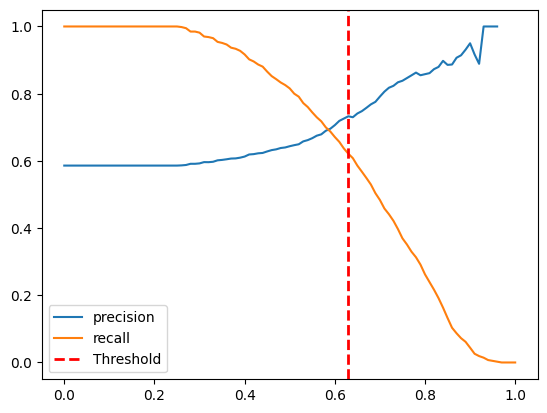

In [18]:
# plot results
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.axvline(x=0.63, color='red', linestyle='--', linewidth=2, label='Threshold')
plt.legend()

In [19]:
# calculate difference
df_scores['difference'] = abs(df_scores.precision - df_scores.recall)

# find min difference
min_difference = df_scores['difference'].min()
df_scores[df_scores['difference'] == min_difference]

,threshold,tp,tn,fp,fn,precision,recall,difference
59,0.59,464,211,203,211,0.695652,0.687407,0.008245


In [ ]:
df_scores[55:65]

,threshold,tp,tn,fp,fn,precision,recall,difference
55,0.55,492,169,245,169,0.667571,0.744327,0.076756
56,0.56,486,180,234,180,0.675000,0.729730,0.054730
57,0.57,478,188,226,188,0.678977,0.717718,0.038740
58,0.58,471,202,212,202,0.689605,0.699851,0.010247
59,0.59,464,211,203,211,0.695652,0.687407,0.008245
60,0.60,457,224,190,224,0.706337,0.671072,0.035265
61,0.61,453,237,177,237,0.719048,0.656522,0.062526
62,0.62,437,249,165,249,0.725914,0.637026,0.088887
63,0.63,425,259,155,259,0.732759,0.621345,0.111414
64,0.64,408,263,151,263,0.729875,0.608048,0.121827


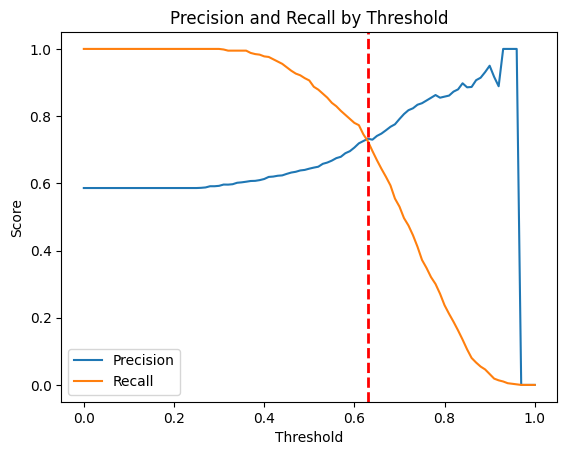

In [22]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(start=0, stop=1.01, step=0.01)
precisions = []
recalls = []

for t in thresholds:
    converted_prediction = (y_pred >= t).astype(int)
    precisions.append(
        precision_score(
            y_val,
            converted_prediction,
            zero_division = 0
        )
    )
    recalls.append(
        recall_score(
            y_val,
            converted_prediction,
            zero_division = 0
        )
    )

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall by Threshold')
plt.axvline(x=0.63, color='red', linestyle='--', linewidth=2)
plt.legend()

# Q4: F1 score

In [26]:
max_f1 = -1
max_threshold = -1
for t, precision, recall in zip(threshold, precisions, recalls):
    if (precision + recall != 0):
        f1 = 2 * (precision * recall) / (precision + recall)
    else: f1 = 0
    # update max
    if max_f1 < f1:
        max_f1 = f1
        max_threshold = t

print(f'Max F1: {max_f1}, Max Threshold: {max_threshold}')

Max F1: 0.7576158940397352, Max Threshold: 0.41000000000000003


# Q5: 5-Fold CV

In [ ]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [31]:
def predict(df_val, dv, model):
    dicts = df_val[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [32]:
from sklearn.model_selection import KFold

In [33]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [43]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

In [45]:
np.std(scores)

np.float64(0.006853233151022138)

# Q6: Hyperparameter Tuning

In [ ]:

for c in [0.000001, 0.001, 1]:

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]


        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)